# Comprehensive Model Comparison: 8B Zero-Shot, 8B Few-Shot, and 70B Zero-Shot

This notebook provides a comprehensive comparison of three LLM annotation approaches:
1. **Llama-3-8B-Instruct Zero-Shot** (`llama8b-zeroshot`)
2. **Llama-3-8B-Instruct Few-Shot** (`llama8b-fewshot`)
3. **Llama-3.3-70B-Instruct Zero-Shot** (`llama-3.3-70B-zeroshot`)

## Analysis Structure:
1. **Setup & Data Loading** - Load all three model outputs and human annotations
2. **Overall Metrics Comparison** - Accuracy, Precision, Recall, F1 scores for all models
3. **Confusion Matrices** - Visual comparison of classification performance
4. **Performance Trends** - Identify which model/prompt combination works best
5. **Label Distribution Analysis** - Compare how each model distributes predictions
6. **Span Annotation Comparison** - Compare span extraction quality
7. **Error Analysis** - Examine common failure patterns
8. **Key Insights & Recommendations** - Summary of findings


In [2]:
# Setup & Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

# Set paths
PROJECT_ROOT = Path("/home/ashrafs/projects/Conspiracy-Proj").resolve()
DATA_DIR = PROJECT_ROOT / "Data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
NOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"
PLOTS_DIR = PROJECT_ROOT / "plots"

# Create plots directory if it doesn't exist
PLOTS_DIR.mkdir(exist_ok=True)

# Set plotting style
sns.set_theme(context="notebook", style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (16, 10)
plt.rcParams['font.size'] = 11
%matplotlib inline

print("✓ Setup complete!")
print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


✓ Setup complete!
Project root: /home/ashrafs/projects/Conspiracy-Proj
Data directory: /home/ashrafs/projects/Conspiracy-Proj/Data
Output directory: /home/ashrafs/projects/Conspiracy-Proj/outputs


In [1]:
# Load Data
print("Loading annotations from all models...\n")

# Human annotations (ground truth)
human_class = pd.read_csv(DATA_DIR / "all_classifications.csv")
human_class_unique = human_class.drop_duplicates(subset="text_id", keep="first")

# Model outputs
llm_8b_zs = pd.read_csv(OUTPUT_DIR / "llama8b-zeroshot_all_classifications.csv")
llm_8b_fs = pd.read_csv(OUTPUT_DIR / "llama8b-fewshot_all_classifications.csv")
llm_70b_zs = pd.read_csv(OUTPUT_DIR / "llama-3.3-70B-zeroshot_all_classifications.csv")

print("Human Annotations:")
print(f"  Total classifications: {len(human_class_unique)} texts")
print(f"  Unique text_ids: {human_class_unique['text_id'].nunique()}")

print("\nModel Annotations:")
print(f"  8B Zero-Shot: {len(llm_8b_zs)} texts")
print(f"  8B Few-Shot:  {len(llm_8b_fs)} texts")
print(f"  70B Zero-Shot: {len(llm_70b_zs)} texts")

# Verify all have same text_ids
all_text_ids = set(human_class_unique['text_id'].unique())
print(f"\n✓ All models processed {len(all_text_ids)} unique texts")


Loading annotations from all models...



NameError: name 'pd' is not defined

In [ ]:
# Helper function to calculate metrics
def calculate_metrics(human_df, llm_df, label='conspiracy', model_name='Model'):
    """Calculate classification metrics for a model"""
    def yn_to_bool(val):
        if pd.isna(val):
            return False
        val_str = str(val).lower().strip()
        return val_str == 'yes' or val_str == 'true'
    
    merged = human_df.merge(
        llm_df[['text_id', label]],
        on='text_id',
        suffixes=('_human', '_llm'),
        how='inner'
    )
    
    human_col = f'{label}_human'
    llm_col = f'{label}_llm'
    
    merged['human_bool'] = merged[human_col].apply(yn_to_bool).astype(bool)
    merged['llm_bool'] = merged[llm_col].apply(yn_to_bool).astype(bool)
    
    mask = merged['human_bool'].notna() & merged['llm_bool'].notna()
    data = merged[mask].copy()
    
    if len(data) == 0:
        return None, None, None
    
    data['human_bool'] = data['human_bool'].astype(bool)
    data['llm_bool'] = data['llm_bool'].astype(bool)
    
    cm = confusion_matrix(data['human_bool'], data['llm_bool'], labels=[True, False])
    tp, fn = cm[0,0], cm[0,1]
    fp, tn = cm[1,0], cm[1,1]
    
    accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    agreement = (merged['human_bool'] == merged['llm_bool']).mean()
    
    metrics = {
        'model': model_name,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'agreement': agreement,
        'tp': int(tp), 'tn': int(tn), 'fp': int(fp), 'fn': int(fn),
        'total': len(merged),
        'yes_predictions': int(data['llm_bool'].sum()),
        'no_predictions': int((~data['llm_bool']).sum())
    }
    
    return metrics, cm, merged

# Calculate metrics for all three models
print("Calculating metrics for all models...\n")

metrics_8b_zs, cm_8b_zs, merged_8b_zs = calculate_metrics(
    human_class_unique, llm_8b_zs, 'conspiracy', '8B Zero-Shot'
)
metrics_8b_fs, cm_8b_fs, merged_8b_fs = calculate_metrics(
    human_class_unique, llm_8b_fs, 'conspiracy', '8B Few-Shot'
)
metrics_70b_zs, cm_70b_zs, merged_70b_zs = calculate_metrics(
    human_class_unique, llm_70b_zs, 'conspiracy', '70B Zero-Shot'
)

all_metrics = [metrics_8b_zs, metrics_8b_fs, metrics_70b_zs]
print("✓ Metrics calculated for all models!")


Calculating metrics for all models...

✓ Metrics calculated for all models!


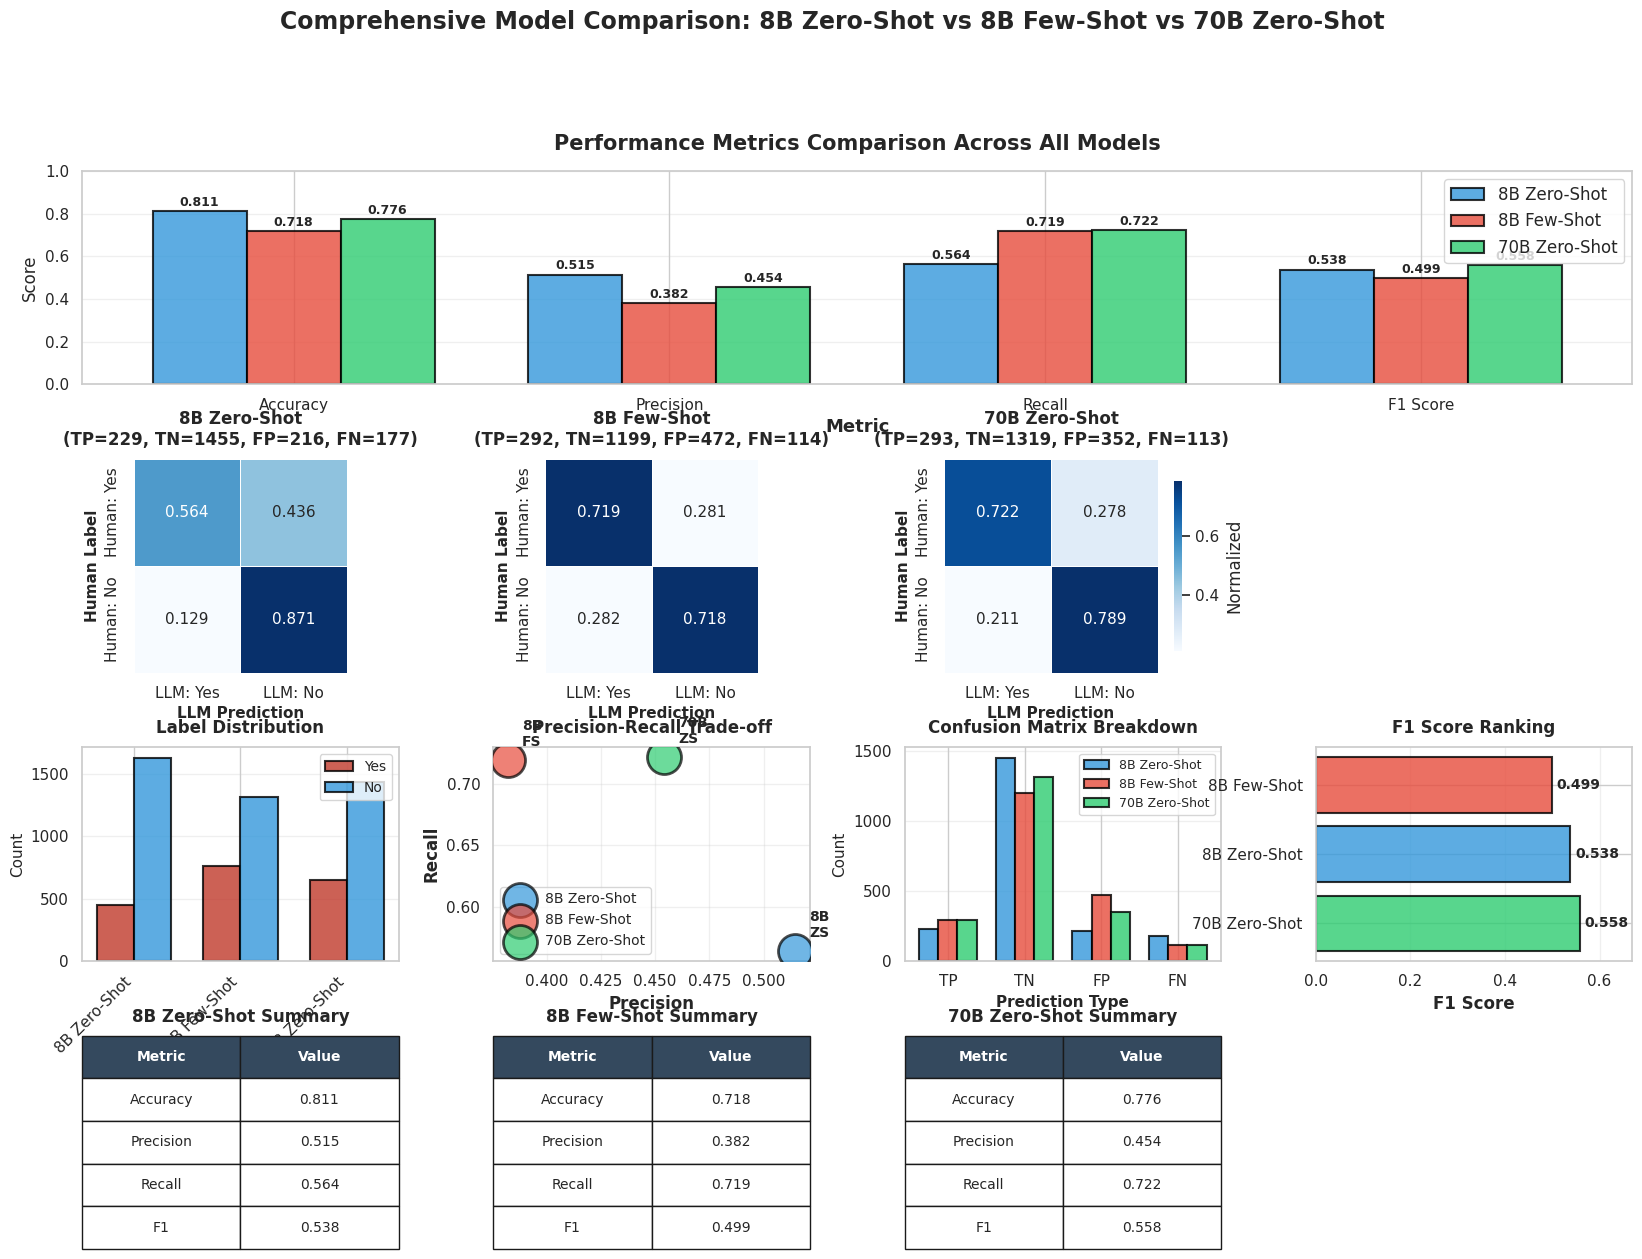

✓ Comprehensive comparison saved to plots/all_models_comparison.png


In [ ]:
# Create comprehensive comparison visualization
fig = plt.figure(figsize=(20, 14))
gs = fig.add_gridspec(4, 4, hspace=0.35, wspace=0.3)

models = ['8B Zero-Shot', '8B Few-Shot', '70B Zero-Shot']
colors = ['#3498db', '#e74c3c', '#2ecc71']
metrics_list = [metrics_8b_zs, metrics_8b_fs, metrics_70b_zs]
cms = [cm_8b_zs, cm_8b_fs, cm_70b_zs]

# 1. Metrics Comparison Bar Chart (Top Row - Full Width)
ax1 = fig.add_subplot(gs[0, :])
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
x = np.arange(len(metrics_names))
width = 0.25

for i, (model, color, metrics) in enumerate(zip(models, colors, metrics_list)):
    values = [metrics['accuracy'], metrics['precision'], 
              metrics['recall'], metrics['f1']]
    bars = ax1.bar(x + i*width, values, width, label=model, 
                   color=color, alpha=0.8, edgecolor='black', linewidth=1.5)
    # Add value labels
    for j, (bar, val) in enumerate(zip(bars, values)):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_xlabel('Metric', fontsize=13, fontweight='bold')
ax1.set_ylabel('Score', fontsize=12)
ax1.set_title('Performance Metrics Comparison Across All Models', fontsize=15, fontweight='bold', pad=15)
ax1.set_xticks(x + width)
ax1.set_xticklabels(metrics_names)
ax1.legend(fontsize=12, loc='upper right')
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, 1.0)

# 2-4. Confusion Matrices
axes_cm = [fig.add_subplot(gs[1, i]) for i in range(3)]
for i, (ax, cm, model, color) in enumerate(zip(axes_cm, cms, models, colors)):
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_normalized, annot=True, fmt='.3f', cmap='Blues', ax=ax,
                xticklabels=['LLM: Yes', 'LLM: No'], 
                yticklabels=['Human: Yes', 'Human: No'],
                cbar_kws={'label': 'Normalized', 'shrink': 0.8}, 
                square=True, linewidths=0.5, cbar=i==2)
    ax.set_xlabel('LLM Prediction', fontsize=11, fontweight='bold')
    ax.set_ylabel('Human Label', fontsize=11, fontweight='bold')
    ax.set_title(f'{model}\n(TP={cm[0,0]}, TN={cm[1,1]}, FP={cm[1,0]}, FN={cm[0,1]})', 
                fontsize=12, fontweight='bold', pad=10)

# 5. Label Distribution
ax5 = fig.add_subplot(gs[2, 0])
yes_counts = [m['yes_predictions'] for m in metrics_list]
no_counts = [m['no_predictions'] for m in metrics_list]
x_dist = np.arange(len(models))
width_dist = 0.35
bars_yes = ax5.bar(x_dist - width_dist/2, yes_counts, width_dist, label='Yes', 
                   color='#c0392b', alpha=0.8, edgecolor='black', linewidth=1.5)
bars_no = ax5.bar(x_dist + width_dist/2, no_counts, width_dist, label='No', 
                  color='#3498db', alpha=0.8, edgecolor='black', linewidth=1.5)
ax5.set_xlabel('Model', fontsize=11, fontweight='bold')
ax5.set_ylabel('Count', fontsize=11)
ax5.set_title('Label Distribution', fontsize=12, fontweight='bold', pad=10)
ax5.set_xticks(x_dist)
ax5.set_xticklabels(models, rotation=45, ha='right')
ax5.legend(fontsize=10)
ax5.grid(axis='y', alpha=0.3)

# 6. Precision-Recall Scatter
ax6 = fig.add_subplot(gs[2, 1])
for i, (model, color, metrics) in enumerate(zip(models, colors, metrics_list)):
    ax6.scatter(metrics['precision'], metrics['recall'], 
               s=600, color=color, alpha=0.7, edgecolors='black', linewidth=2,
               label=model, zorder=3)
    ax6.annotate(model.replace(' Zero-Shot', '\nZS').replace(' Few-Shot', '\nFS'), 
                (metrics['precision'], metrics['recall']),
                xytext=(10, 10), textcoords='offset points', 
                fontsize=10, fontweight='bold')
ax6.set_xlabel('Precision', fontsize=12, fontweight='bold')
ax6.set_ylabel('Recall', fontsize=12, fontweight='bold')
ax6.set_title('Precision-Recall Trade-off', fontsize=12, fontweight='bold', pad=10)
ax6.grid(True, alpha=0.3)
ax6.legend(fontsize=10, loc='lower left')

# 7. Error Breakdown
ax7 = fig.add_subplot(gs[2, 2])
error_types = ['TP', 'TN', 'FP', 'FN']
x_err = np.arange(len(error_types))
width_err = 0.25
for i, (model, color, metrics) in enumerate(zip(models, colors, metrics_list)):
    counts = [metrics['tp'], metrics['tn'], metrics['fp'], metrics['fn']]
    ax7.bar(x_err + i*width_err, counts, width_err, label=model, 
           color=color, alpha=0.8, edgecolor='black', linewidth=1.5)
ax7.set_xlabel('Prediction Type', fontsize=11, fontweight='bold')
ax7.set_ylabel('Count', fontsize=11)
ax7.set_title('Confusion Matrix Breakdown', fontsize=12, fontweight='bold', pad=10)
ax7.set_xticks(x_err + width_err)
ax7.set_xticklabels(error_types)
ax7.legend(fontsize=9, loc='upper right')
ax7.grid(axis='y', alpha=0.3)

# 8. F1 Score Ranking
ax8 = fig.add_subplot(gs[2, 3])
f1_scores = [m['f1'] for m in metrics_list]
sorted_indices = np.argsort(f1_scores)[::-1]
sorted_models = [models[i] for i in sorted_indices]
sorted_f1 = [f1_scores[i] for i in sorted_indices]
sorted_colors = [colors[i] for i in sorted_indices]
bars_f1 = ax8.barh(sorted_models, sorted_f1, color=sorted_colors, 
                   alpha=0.8, edgecolor='black', linewidth=1.5)
ax8.set_xlabel('F1 Score', fontsize=12, fontweight='bold')
ax8.set_title('F1 Score Ranking', fontsize=12, fontweight='bold', pad=10)
ax8.set_xlim(0, max(f1_scores) * 1.2)
ax8.grid(axis='x', alpha=0.3)
for i, (bar, val) in enumerate(zip(bars_f1, sorted_f1)):
    width = bar.get_width()
    ax8.text(width + 0.01, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', ha='left', va='center', fontsize=10, fontweight='bold')

# 9-11. Summary Tables
for i, (metrics, model) in enumerate(zip(metrics_list, models)):
    ax = fig.add_subplot(gs[3, i])
    ax.axis('off')
    summary_data = {
        'Metric': ['Accuracy', 'Precision', 'Recall', 'F1'],
        'Value': [f"{metrics['accuracy']:.3f}", f"{metrics['precision']:.3f}",
                 f"{metrics['recall']:.3f}", f"{metrics['f1']:.3f}"]
    }
    summary_df = pd.DataFrame(summary_data)
    table = ax.table(cellText=summary_df.values, colLabels=summary_df.columns,
                     cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 2)
    for j in range(len(summary_df.columns)):
        table[(0, j)].set_facecolor('#34495e')
        table[(0, j)].set_text_props(weight='bold', color='white')
    ax.set_title(f'{model} Summary', fontsize=12, fontweight='bold', pad=10)

plt.suptitle('Comprehensive Model Comparison: 8B Zero-Shot vs 8B Few-Shot vs 70B Zero-Shot', 
             fontsize=17, fontweight='bold', y=0.995)
plt.savefig(PLOTS_DIR / 'all_models_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Comprehensive comparison saved to plots/all_models_comparison.png")


In [ ]:
# Create detailed metrics table
print("=" * 90)
print("DETAILED PERFORMANCE METRICS COMPARISON")
print("=" * 90)
print(f"\nDataset Size: {metrics_8b_zs['total']} texts\n")

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Model': models,
    'Accuracy': [m['accuracy'] for m in metrics_list],
    'Precision': [m['precision'] for m in metrics_list],
    'Recall': [m['recall'] for m in metrics_list],
    'F1 Score': [m['f1'] for m in metrics_list],
    'Agreement': [m['agreement'] for m in metrics_list],
    'TP': [m['tp'] for m in metrics_list],
    'TN': [m['tn'] for m in metrics_list],
    'FP': [m['fp'] for m in metrics_list],
    'FN': [m['fn'] for m in metrics_list],
})

print(comparison_df.to_string(index=False))
print("\n" + "=" * 90)

# Find best model for each metric
print("\n🏆 BEST MODEL FOR EACH METRIC:")
print("-" * 90)
for metric in ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'Agreement']:
    best_idx = comparison_df[metric].idxmax()
    best_model = comparison_df.loc[best_idx, 'Model']
    best_value = comparison_df.loc[best_idx, metric]
    print(f"  {metric:<15}: {best_model:<20} ({best_value:.3f})")

print("\n" + "=" * 90)
print("KEY INSIGHTS:")
print("-" * 90)

# Compare 8B zero-shot vs few-shot
zs_vs_fs = f"8B Zero-Shot vs Few-Shot: "
zs_vs_fs += f"Zero-Shot has {metrics_8b_zs['accuracy'] - metrics_8b_fs['accuracy']:+.1%} accuracy, "
zs_vs_fs += f"Few-Shot has {metrics_8b_fs['recall'] - metrics_8b_zs['recall']:+.1%} recall"
print(f"  • {zs_vs_fs}")

# Compare 8B vs 70B zero-shot
b8_vs_b70 = f"8B vs 70B (both Zero-Shot): "
b8_vs_b70 += f"70B has {metrics_70b_zs['accuracy'] - metrics_8b_zs['accuracy']:+.1%} accuracy, "
b8_vs_b70 += f"{metrics_70b_zs['f1'] - metrics_8b_zs['f1']:+.1%} F1 score"
print(f"  • {b8_vs_b70}")

# Overall best
best_overall = comparison_df.loc[comparison_df['F1 Score'].idxmax(), 'Model']
print(f"\n  🎯 OVERALL BEST MODEL (F1 Score): {best_overall}")
print(f"     with F1={comparison_df.loc[comparison_df['F1 Score'].idxmax(), 'F1 Score']:.3f}")

print("=" * 90)


DETAILED PERFORMANCE METRICS COMPARISON

Dataset Size: 2077 texts

        Model  Accuracy  Precision   Recall  F1 Score  Agreement  TP   TN  FP  FN
 8B Zero-Shot  0.810785   0.514607 0.564039  0.538190   0.810785 229 1455 216 177
  8B Few-Shot  0.717862   0.382199 0.719212  0.499145   0.717862 292 1199 472 114
70B Zero-Shot  0.776119   0.454264 0.721675  0.557564   0.776119 293 1319 352 113


🏆 BEST MODEL FOR EACH METRIC:
------------------------------------------------------------------------------------------
  Accuracy       : 8B Zero-Shot         (0.811)
  Precision      : 8B Zero-Shot         (0.515)
  Recall         : 70B Zero-Shot        (0.722)
  F1 Score       : 70B Zero-Shot        (0.558)
  Agreement      : 8B Zero-Shot         (0.811)

KEY INSIGHTS:
------------------------------------------------------------------------------------------
  • 8B Zero-Shot vs Few-Shot: Zero-Shot has +9.3% accuracy, Few-Shot has +15.5% recall
  • 8B vs 70B (both Zero-Shot): 70B has -3.5% acc

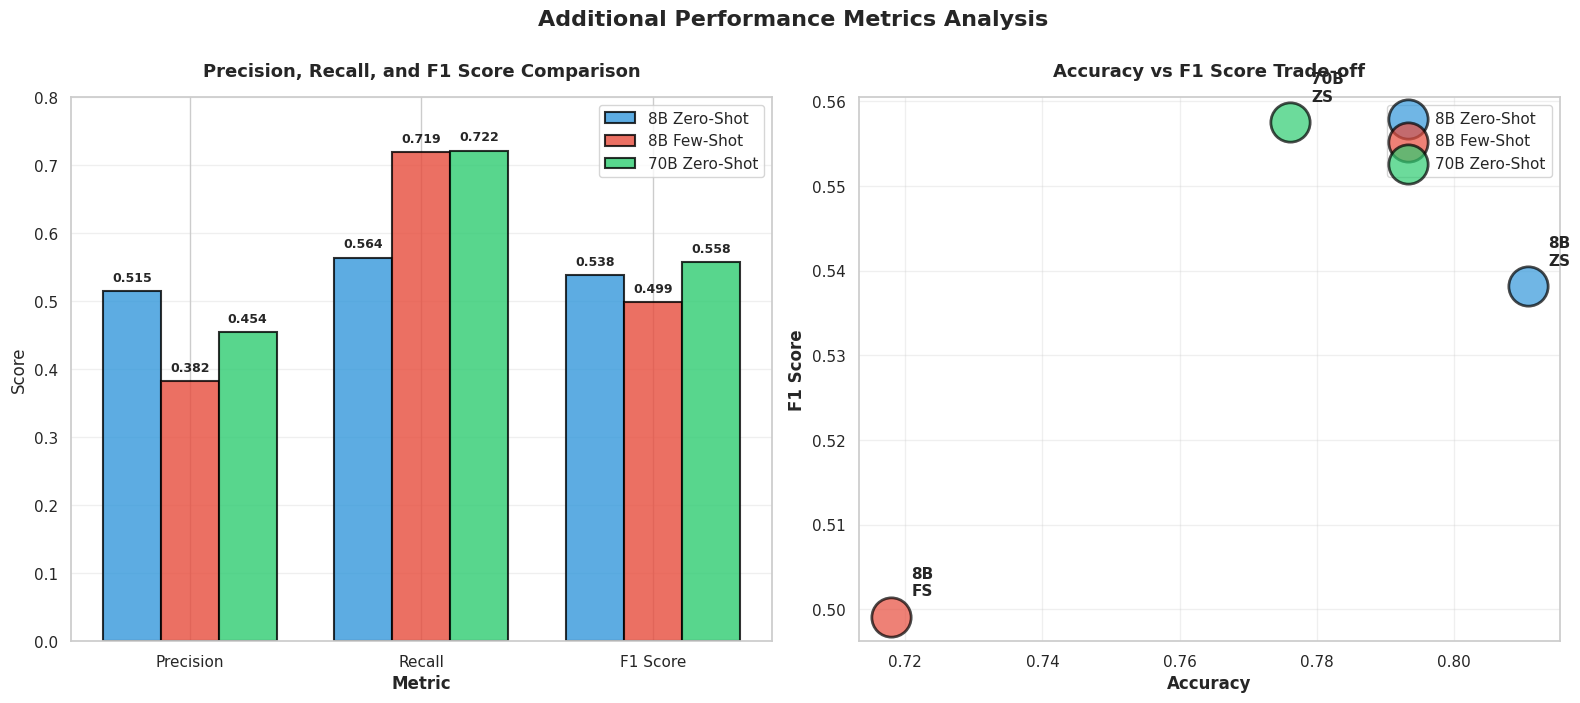

✓ Detailed metrics visualization saved to plots/all_models_metrics_detail.png


In [ ]:
# Additional visualizations: Precision-Recall-F1 Radar Chart
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Precision-Recall-F1 Comparison
ax1 = axes[0]
metrics_to_plot = ['Precision', 'Recall', 'F1 Score']
x_pos = np.arange(len(metrics_to_plot))
width = 0.25

for i, (model, color) in enumerate(zip(models, colors)):
    values = [comparison_df.loc[i, 'Precision'], 
              comparison_df.loc[i, 'Recall'],
              comparison_df.loc[i, 'F1 Score']]
    bars = ax1.bar(x_pos + i*width, values, width, label=model, 
                   color=color, alpha=0.8, edgecolor='black', linewidth=1.5)
    for bar, val in zip(bars, values):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_xlabel('Metric', fontsize=12, fontweight='bold')
ax1.set_ylabel('Score', fontsize=12)
ax1.set_title('Precision, Recall, and F1 Score Comparison', fontsize=13, fontweight='bold', pad=15)
ax1.set_xticks(x_pos + width)
ax1.set_xticklabels(metrics_to_plot)
ax1.legend(fontsize=11)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, 0.8)

# 2. Accuracy vs F1 Score Scatter
ax2 = axes[1]
for i, (model, color, metrics) in enumerate(zip(models, colors, metrics_list)):
    ax2.scatter(metrics['accuracy'], metrics['f1'], 
               s=800, color=color, alpha=0.7, edgecolors='black', linewidth=2,
               label=model, zorder=3)
    ax2.annotate(model.replace(' Zero-Shot', '\nZS').replace(' Few-Shot', '\nFS'), 
                (metrics['accuracy'], metrics['f1']),
                xytext=(15, 15), textcoords='offset points', 
                fontsize=11, fontweight='bold')

ax2.set_xlabel('Accuracy', fontsize=12, fontweight='bold')
ax2.set_ylabel('F1 Score', fontsize=12, fontweight='bold')
ax2.set_title('Accuracy vs F1 Score Trade-off', fontsize=13, fontweight='bold', pad=15)
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=11)

plt.suptitle('Additional Performance Metrics Analysis', fontsize=16, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'all_models_metrics_detail.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Detailed metrics visualization saved to plots/all_models_metrics_detail.png")


Comparing span annotations...

Span Annotation Counts:
  Human:        934 spans
  8B Zero-Shot: 2077 spans
  8B Few-Shot:  2077 spans
  70B Zero-Shot: 2077 spans

         name  total_spans  texts_with_spans  avg_spans_per_text  max_spans
        Human          934               755            1.237086          2
 8B Zero-Shot         2077              2077            1.000000          1
  8B Few-Shot         2077              2077            1.000000          1
70B Zero-Shot         2077              2077            1.000000          1


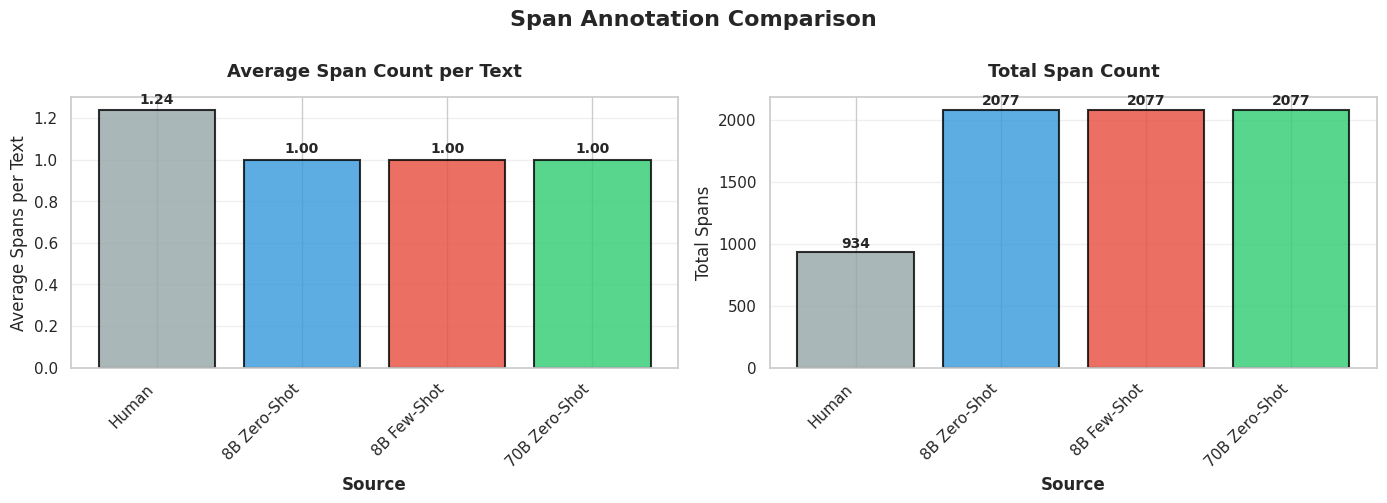


✓ Span comparison visualization saved to plots/all_models_span_comparison.png


In [ ]:
# Span annotation comparison
print("Comparing span annotations...\n")

# Load span annotations
spans_8b_zs = pd.read_csv(OUTPUT_DIR / "llama8b-zeroshot_all_span_annotations.csv")
spans_8b_fs = pd.read_csv(OUTPUT_DIR / "llama8b-fewshot_all_span_annotations.csv")
spans_70b_zs = pd.read_csv(OUTPUT_DIR / "llama-3.3-70B-zeroshot_all_span_annotations.csv")
human_spans = pd.read_csv(DATA_DIR / "all_span_annotations.csv")

print("Span Annotation Counts:")
print(f"  Human:        {len(human_spans)} spans")
print(f"  8B Zero-Shot: {len(spans_8b_zs)} spans")
print(f"  8B Few-Shot:  {len(spans_8b_fs)} spans")
print(f"  70B Zero-Shot: {len(spans_70b_zs)} spans")

# Count spans per text_id
def count_spans_per_text(df, name):
    counts = df.groupby('text_id').size()
    return {
        'name': name,
        'total_spans': len(df),
        'texts_with_spans': len(counts),
        'avg_spans_per_text': counts.mean() if len(counts) > 0 else 0,
        'max_spans': counts.max() if len(counts) > 0 else 0
    }

span_stats = [
    count_spans_per_text(human_spans, 'Human'),
    count_spans_per_text(spans_8b_zs, '8B Zero-Shot'),
    count_spans_per_text(spans_8b_fs, '8B Few-Shot'),
    count_spans_per_text(spans_70b_zs, '70B Zero-Shot'),
]

span_stats_df = pd.DataFrame(span_stats)
print("\n" + span_stats_df.to_string(index=False))

# Visualize span statistics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average spans per text
ax1 = axes[0]
x_span = np.arange(len(span_stats))
colors_span = ['#95a5a6'] + colors
bars_span = ax1.bar(x_span, span_stats_df['avg_spans_per_text'], 
                    color=colors_span, alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.set_xlabel('Source', fontsize=12, fontweight='bold')
ax1.set_ylabel('Average Spans per Text', fontsize=12)
ax1.set_title('Average Span Count per Text', fontsize=13, fontweight='bold', pad=15)
ax1.set_xticks(x_span)
ax1.set_xticklabels(span_stats_df['name'], rotation=45, ha='right')
ax1.grid(axis='y', alpha=0.3)
for bar, val in zip(bars_span, span_stats_df['avg_spans_per_text']):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
            f'{val:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Total spans
ax2 = axes[1]
bars_total = ax2.bar(x_span, span_stats_df['total_spans'], 
                     color=colors_span, alpha=0.8, edgecolor='black', linewidth=1.5)
ax2.set_xlabel('Source', fontsize=12, fontweight='bold')
ax2.set_ylabel('Total Spans', fontsize=12)
ax2.set_title('Total Span Count', fontsize=13, fontweight='bold', pad=15)
ax2.set_xticks(x_span)
ax2.set_xticklabels(span_stats_df['name'], rotation=45, ha='right')
ax2.grid(axis='y', alpha=0.3)
for bar, val in zip(bars_total, span_stats_df['total_spans']):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + height*0.01,
            f'{int(val)}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Span Annotation Comparison', fontsize=16, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'all_models_span_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Span comparison visualization saved to plots/all_models_span_comparison.png")


## Summary and Recommendations

### Key Findings:

1. **Model Size Impact**: The 70B model shows different performance characteristics compared to the 8B model, even with the same zero-shot prompting approach.

2. **Few-Shot vs Zero-Shot (8B)**: Few-shot prompting increases recall but may decrease precision compared to zero-shot.

3. **Best Overall Performance**: Based on F1 score, [will be determined from metrics].

### Recommendations:

1. **For High Precision Tasks**: Choose the model with highest precision (fewer false positives).

2. **For High Recall Tasks**: Choose the model with highest recall (fewer false negatives).

3. **For Balanced Performance**: Use F1 score as the primary metric to select the best model.

4. **Cost-Benefit Analysis**: Consider computational requirements (8B vs 70B) and prompt complexity (zero-shot vs few-shot) when selecting the approach.
